In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import etunc.config as cfg
import etunc.edges as edges
import etunc.grid as rg
import etunc.plotting as plotting
import etunc.temporal as temporal

In [2]:
bs = xr.open_dataset(cfg.output_dir(cfg.PROC_ROOT, "fppe", "qbin", "199501-201412", "lai15_ai15") / "fppe.et.qbin_pooled_all.1deg.199501-201412.nc")

In [3]:
fppe_dmean = bs["et"].isel(member=slice(1, None)) - bs["et"].isel(member=0)

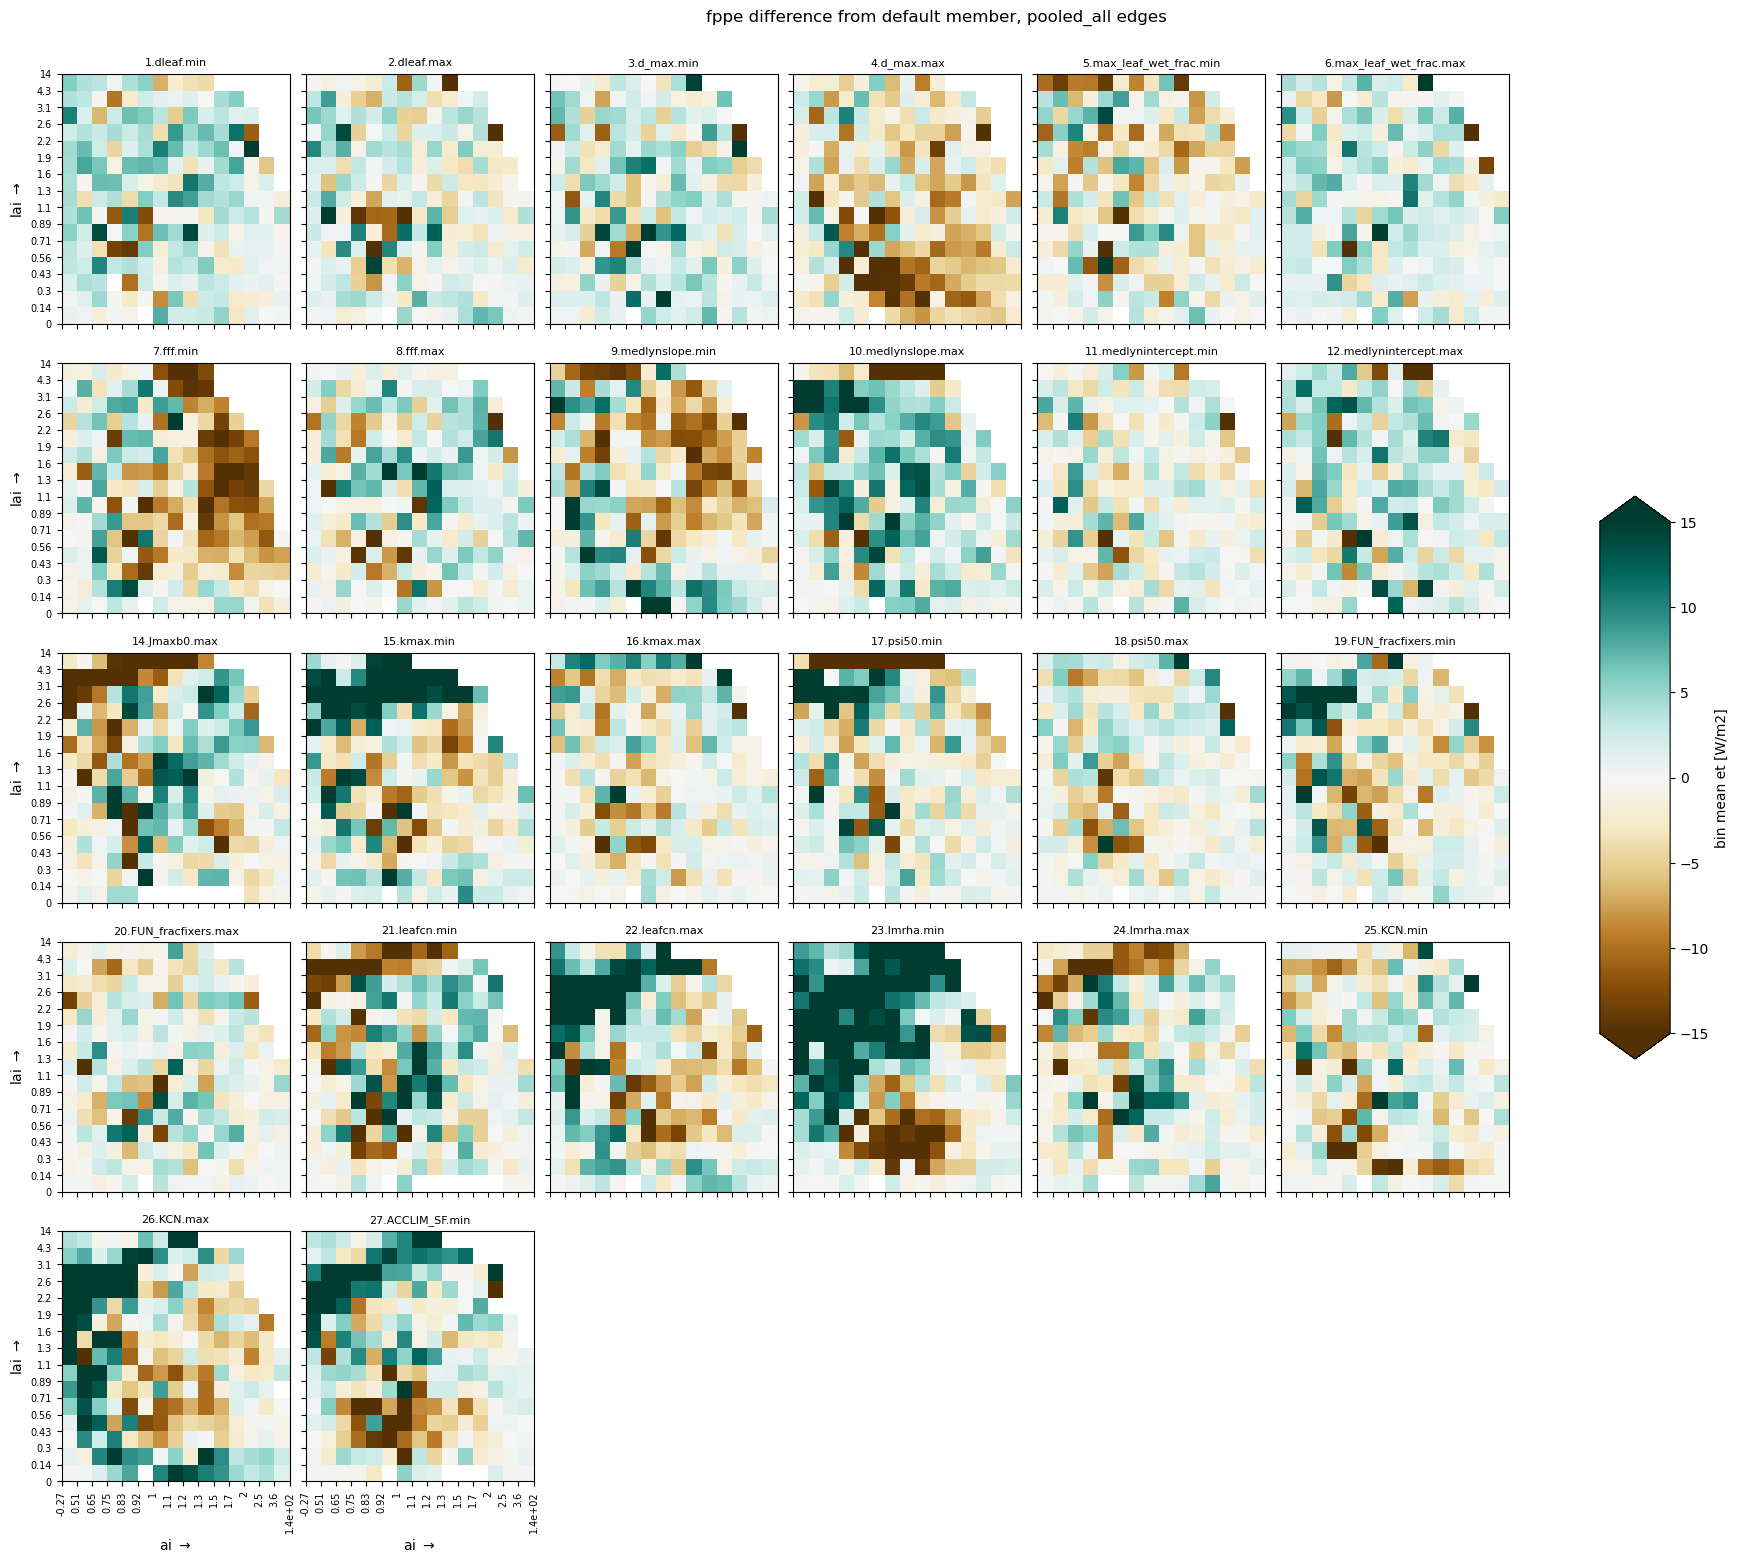

In [7]:
fig = plotting.plot_bin_means(fppe_dmean, "member", title="fppe difference from default member, pooled_all edges", fout=None, cmap="BrBG", vmin=-15, vmax=15)

In [4]:
FAMILIES = cfg.FAMILIES  # every family pooled into the common area and the pooled_all edges
TIME_SLICE = cfg.TIME_SLICE
TARGET_RES = cfg.TARGET_RES
N_BINS = {"lai": cfg.N_YBINS, "ai": cfg.N_XBINS}
FIG_ROOT = cfg.FIG_ROOT / "all"

In [5]:
period = temporal.format_time_period(TIME_SLICE)
grid = rg.grid_tag(TARGET_RES)

print("=== Binning inputs ===")
inputs = {}
for family in FAMILIES:
    path = cfg.inputs_path(family, grid, period)
    if not path.exists():
        raise FileNotFoundError(f"No {family} inputs at {path}; run scripts/prep_{family}.py first")
    inputs[family] = xr.open_dataset(path)
    n_sources = len(set(inputs[family]["source"].values.tolist()))
    print(f"{family:5}: {inputs[family].sizes['member']} members, {n_sources} sources, "
            f"{inputs[family].attrs['time_period']}  {path}")

=== Binning inputs ===
obs  : 48 members, 48 sources, 200001-200512  /glade/derecho/scratch/bbuchovecky/et_unc/proc/obs/obs.inputs.1deg.199501-201412.nc
cmip : 44 members, 44 sources, 199501-201412  /glade/derecho/scratch/bbuchovecky/et_unc/proc/cmip/cmip.inputs.1deg.199501-201412.nc
fppe : 27 members, 27 sources, 199501-201412  /glade/derecho/scratch/bbuchovecky/et_unc/proc/fppe/fppe.inputs.1deg.199501-201412.nc
lens : 50 members, 50 sources, 199501-201412  /glade/derecho/scratch/bbuchovecky/et_unc/proc/lens/lens.inputs.1deg.199501-201412.nc



=== 12. Common area mask ===


obs     :  11332 valid gridcells (1.026e+08 km2); the common area loses   1050 gridcells (1.013e+07 km2, 9.9%)
cmip    :  12137 valid gridcells (1.105e+08 km2); the common area loses   1855 gridcells (1.803e+07 km2, 16.3%)
fppe    :  14669 valid gridcells (1.316e+08 km2); the common area loses   4387 gridcells (3.917e+07 km2, 29.8%)
lens    :  14831 valid gridcells (1.328e+08 km2); the common area loses   4549 gridcells (4.037e+07 km2, 30.4%)
common  :  10282 gridcells (9.242e+07 km2)


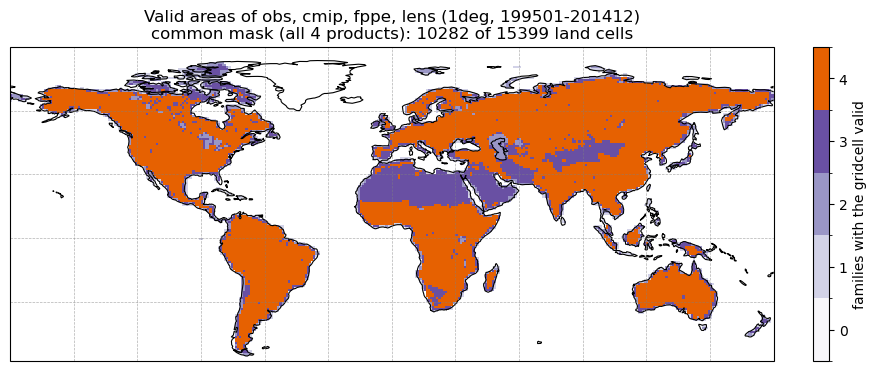

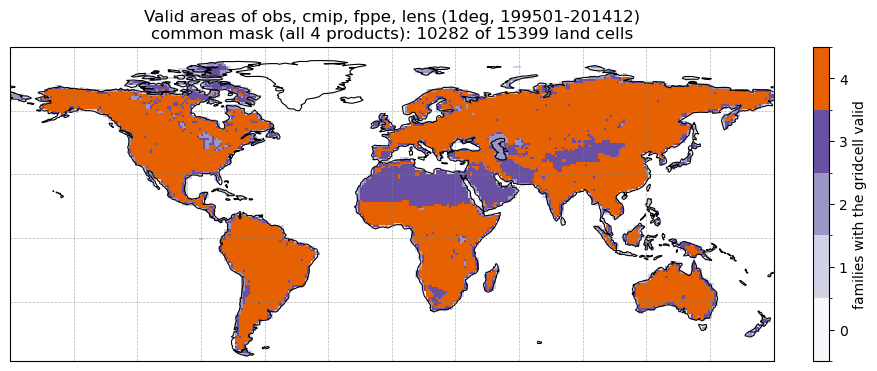

In [6]:
# 12. Common area mask: gridcells valid in every member of every family
print("\n=== 12. Common area mask ===")
valid = {family: rg.valid_area(ds) for family, ds in inputs.items()}
area = rg.common_area(valid)
valid_all = xr.concat(list(valid.values()), dim="family").assign_coords(family=list(valid))
area_mask = xr.Dataset({
    "area_mask": area.astype("i1").assign_attrs(
        long_name="gridcells where ET (any year), LAI and AI are valid in every member of every family"),
    "valid_area": valid_all.astype("i1").assign_attrs(long_name="each family's own valid area"),
}, attrs={"families": list(inputs), "time_period": period, "grid": grid})
plotting.plot_mask_agreement(
    valid_all.rename(family="product"), valid_all.any("family"),
    title=f"Valid areas of {', '.join(inputs)} ({grid}, {period})", label="families with the gridcell valid",
    highlight_common=True, fout=None,
)

In [10]:
inputs["obs"]["lai"].pr_product.values

array(['GPCPv2.3', 'GPCPv2.3', 'ERA5', 'ERA5', 'GPCPv2.3', 'GPCPv2.3',
       'ERA5', 'ERA5', 'GPCPv2.3', 'GPCPv2.3', 'ERA5', 'ERA5', 'GPCPv2.3',
       'GPCPv2.3', 'ERA5', 'ERA5', 'GPCPv2.3', 'GPCPv2.3', 'ERA5', 'ERA5',
       'GPCPv2.3', 'GPCPv2.3', 'ERA5', 'ERA5', 'GPCPv2.3', 'GPCPv2.3',
       'ERA5', 'ERA5', 'GPCPv2.3', 'GPCPv2.3', 'ERA5', 'ERA5', 'GPCPv2.3',
       'GPCPv2.3', 'ERA5', 'ERA5', 'GPCPv2.3', 'GPCPv2.3', 'ERA5', 'ERA5',
       'GPCPv2.3', 'GPCPv2.3', 'ERA5', 'ERA5', 'GPCPv2.3', 'GPCPv2.3',
       'ERA5', 'ERA5'], dtype='<U8')

In [17]:
# inputs["cmip"]["et"].sel(source="CAMS-CSM1-0.r1i1p1f2").plot(col="year", col_wrap=5)

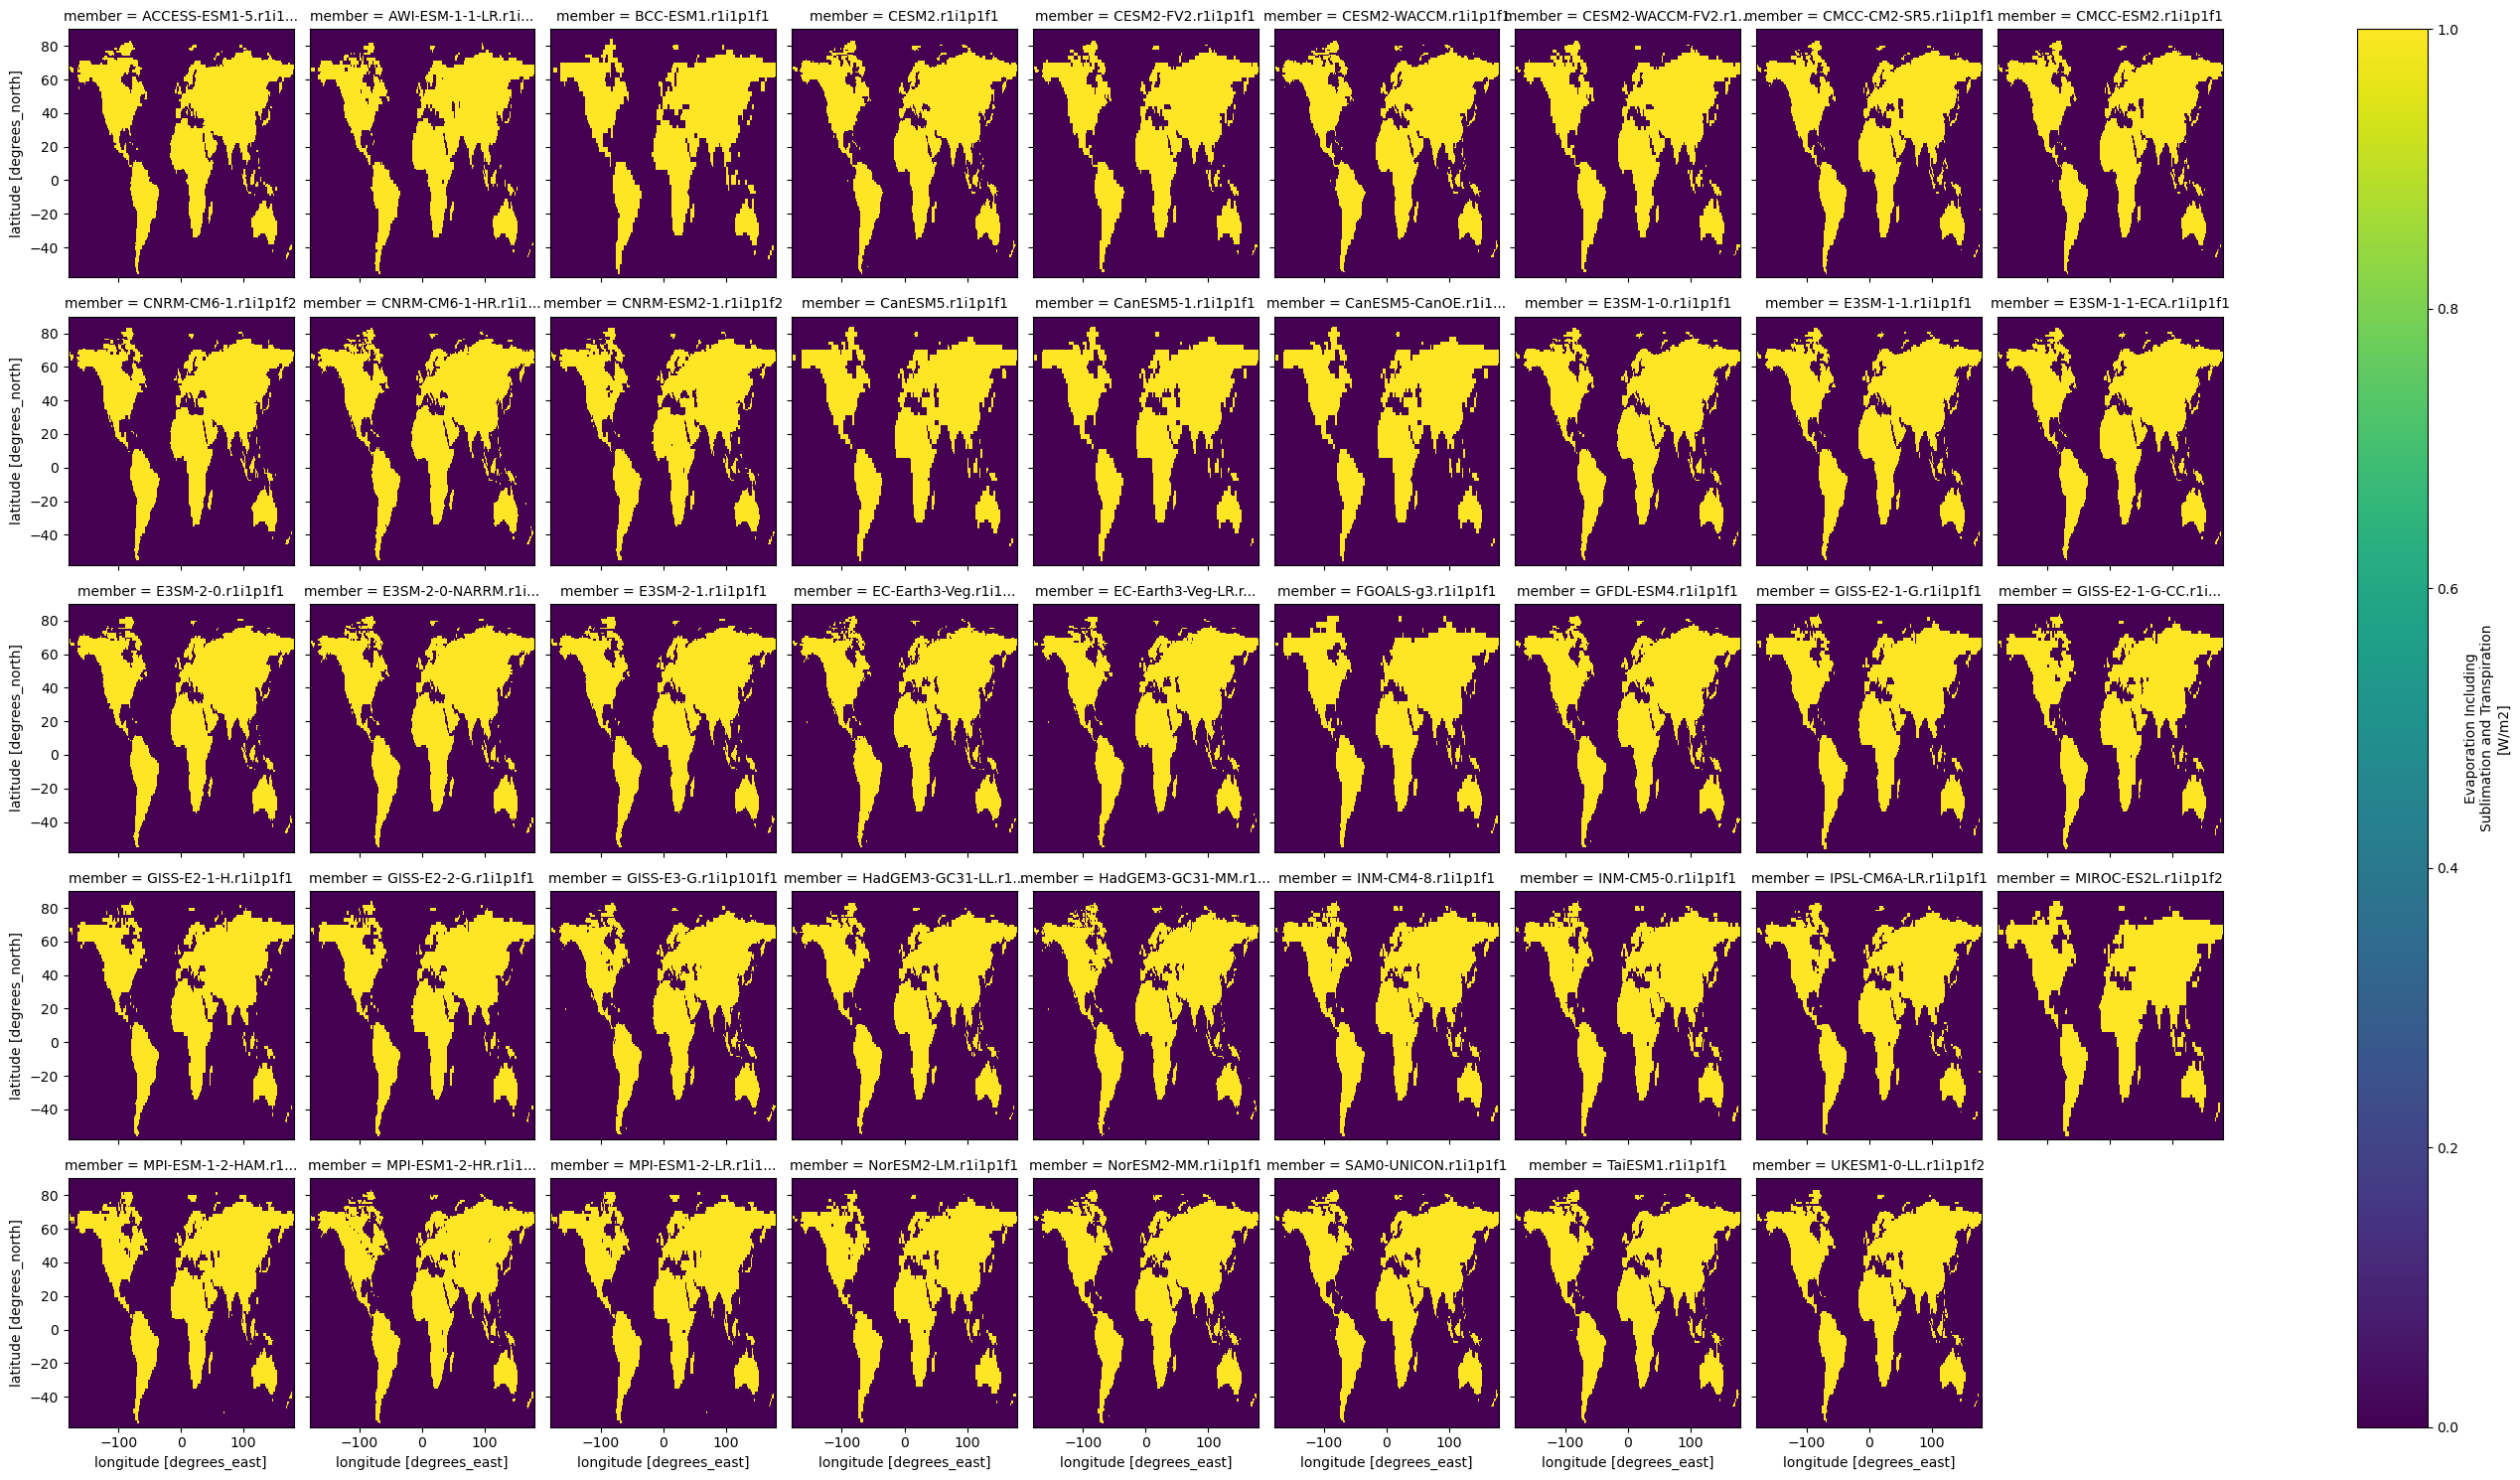

In [8]:
inputs["cmip"]["et"].notnull().any(dim="year").plot(col="member", col_wrap=9)

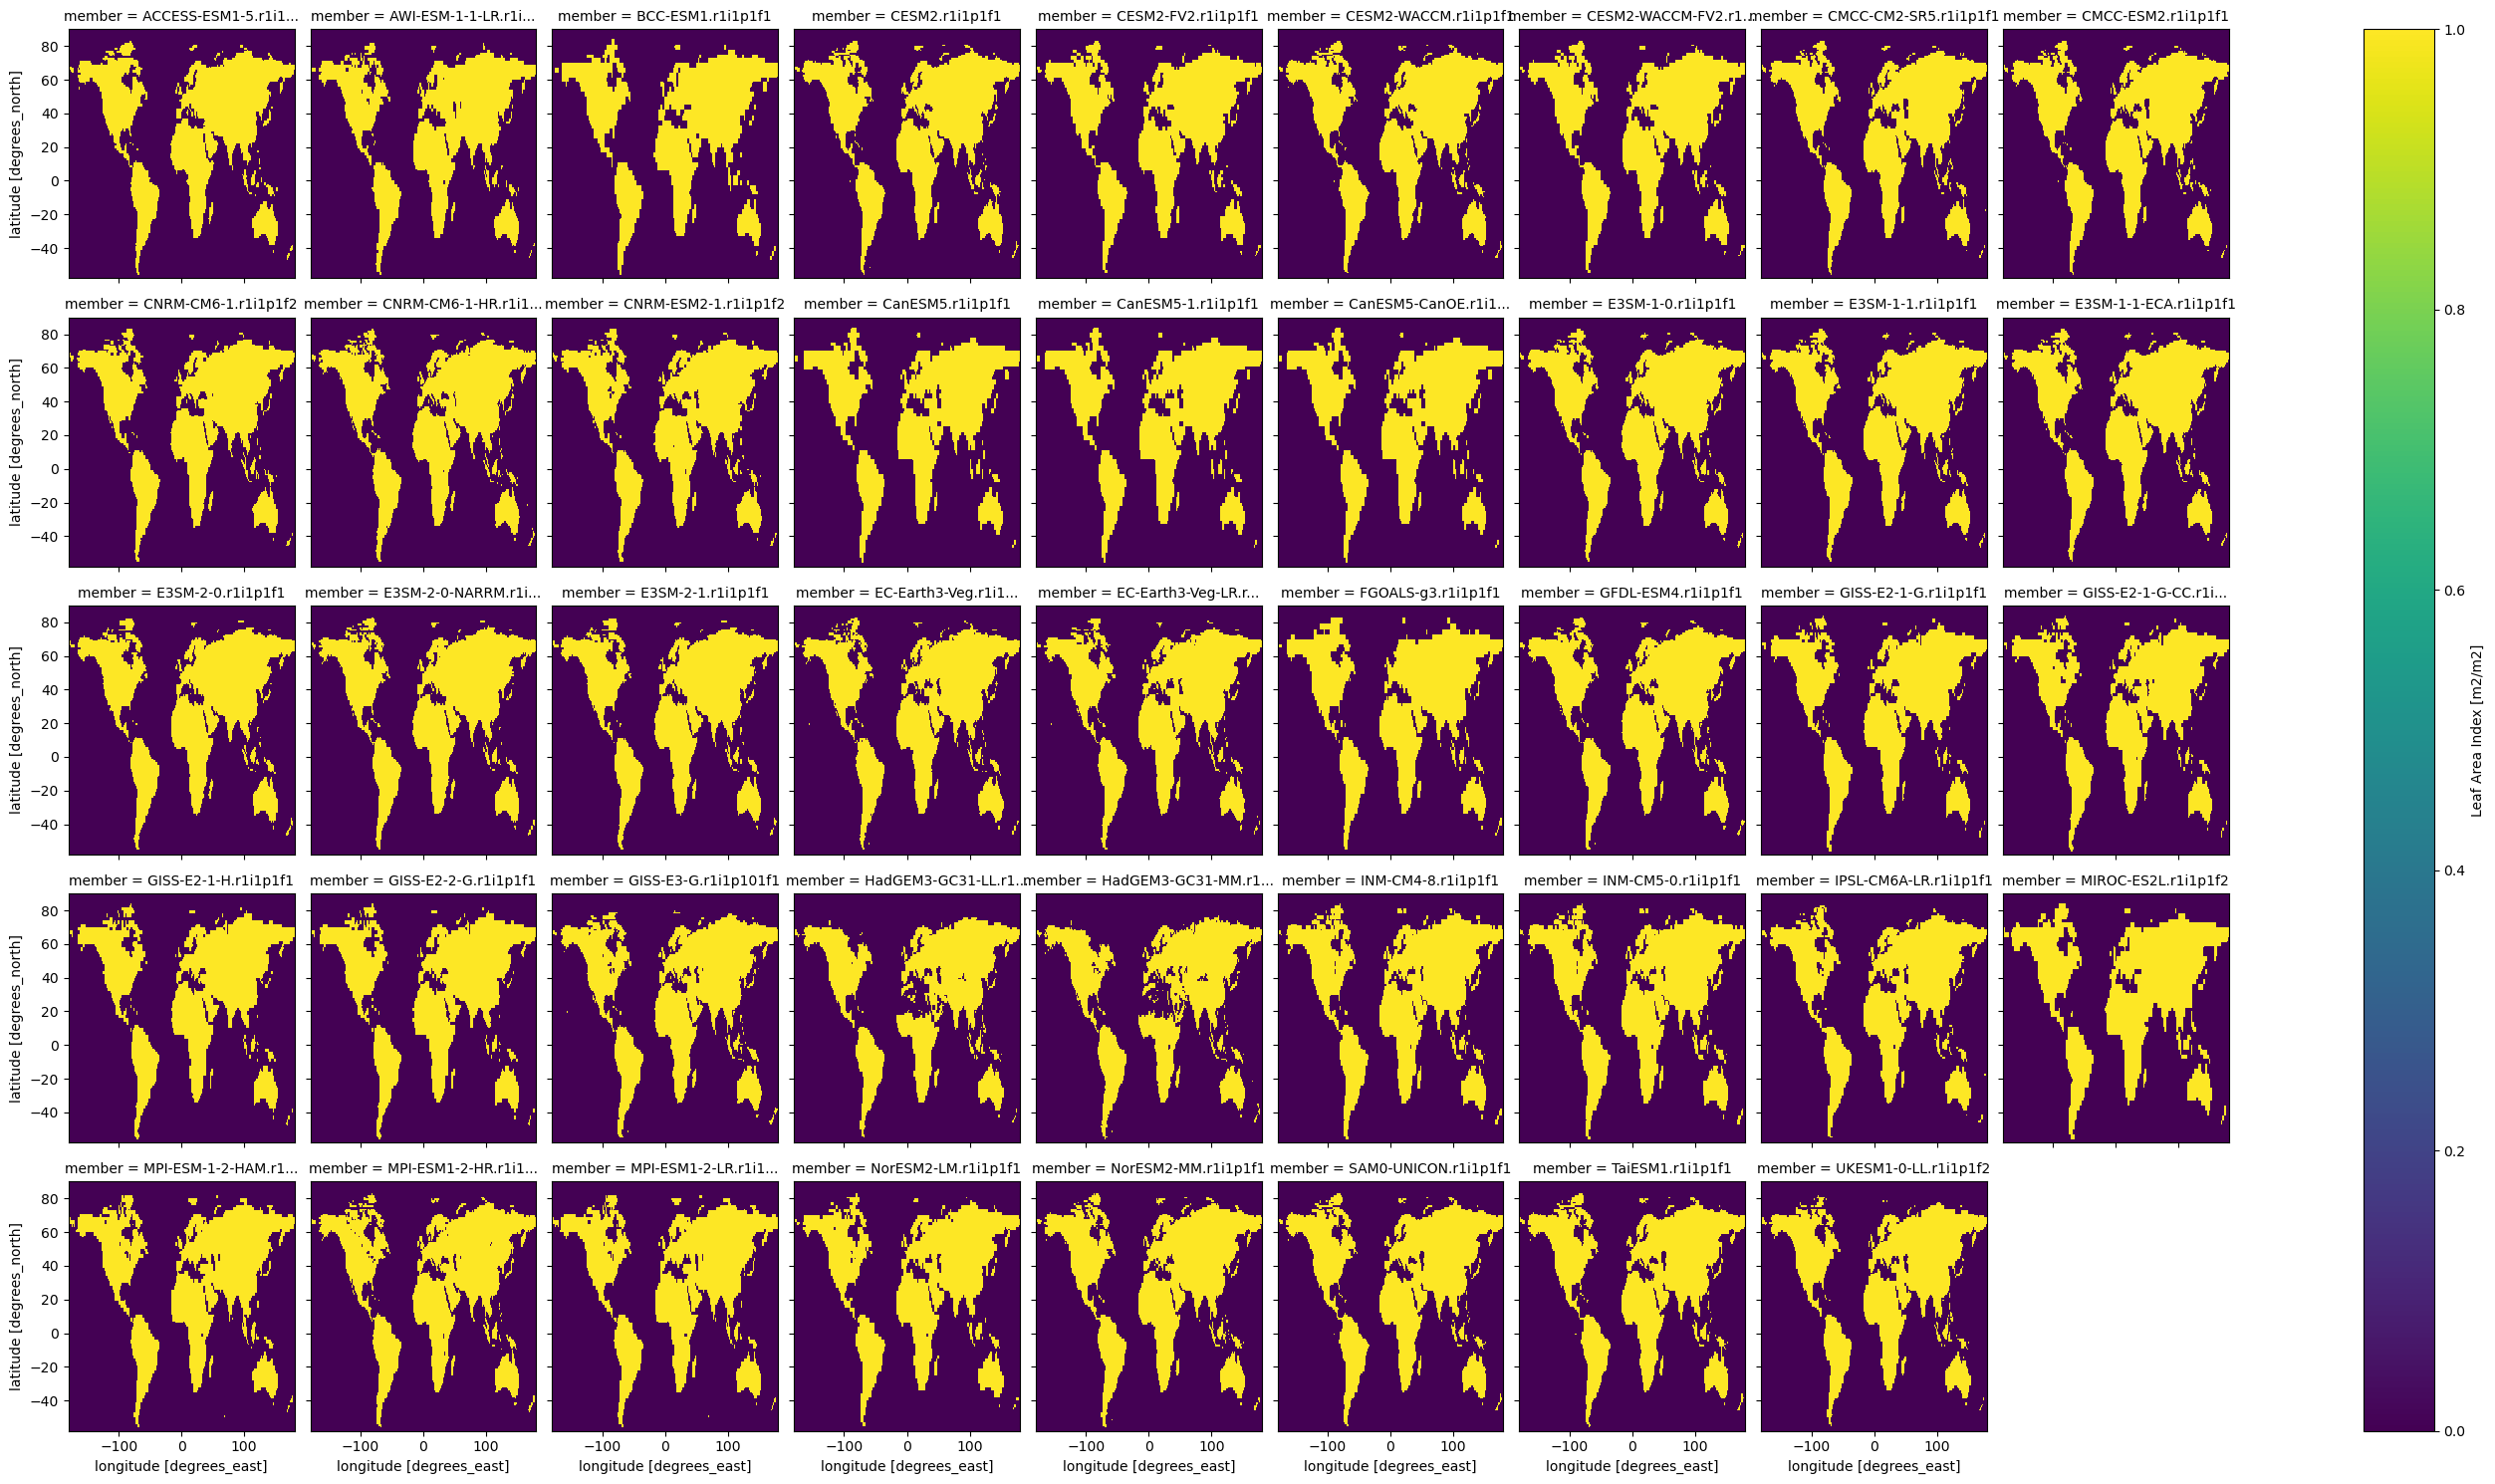

In [18]:
inputs["cmip"]["lai"].notnull().plot(col="member", col_wrap=9)
# HadGEM3-GC31-MM/LL

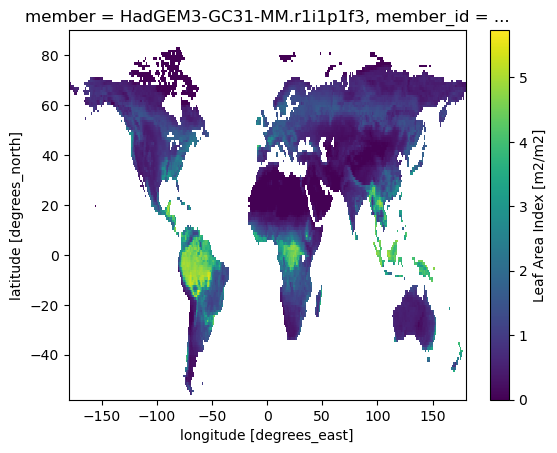

In [9]:
inputs["cmip"]["lai"].sel(source="HadGEM3-GC31-MM").plot()
# HadGEM3-GC31-MM/LL

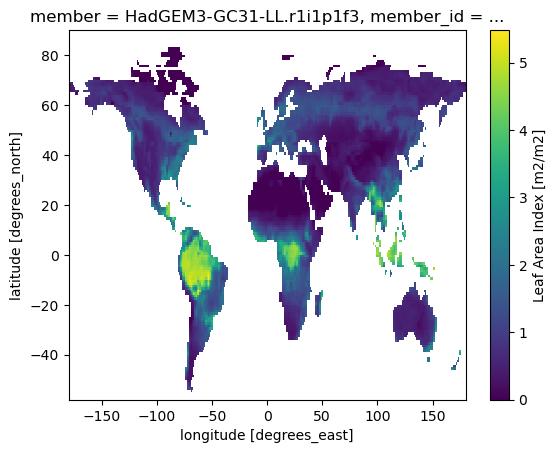

In [10]:
inputs["cmip"]["lai"].sel(source="HadGEM3-GC31-LL").plot()

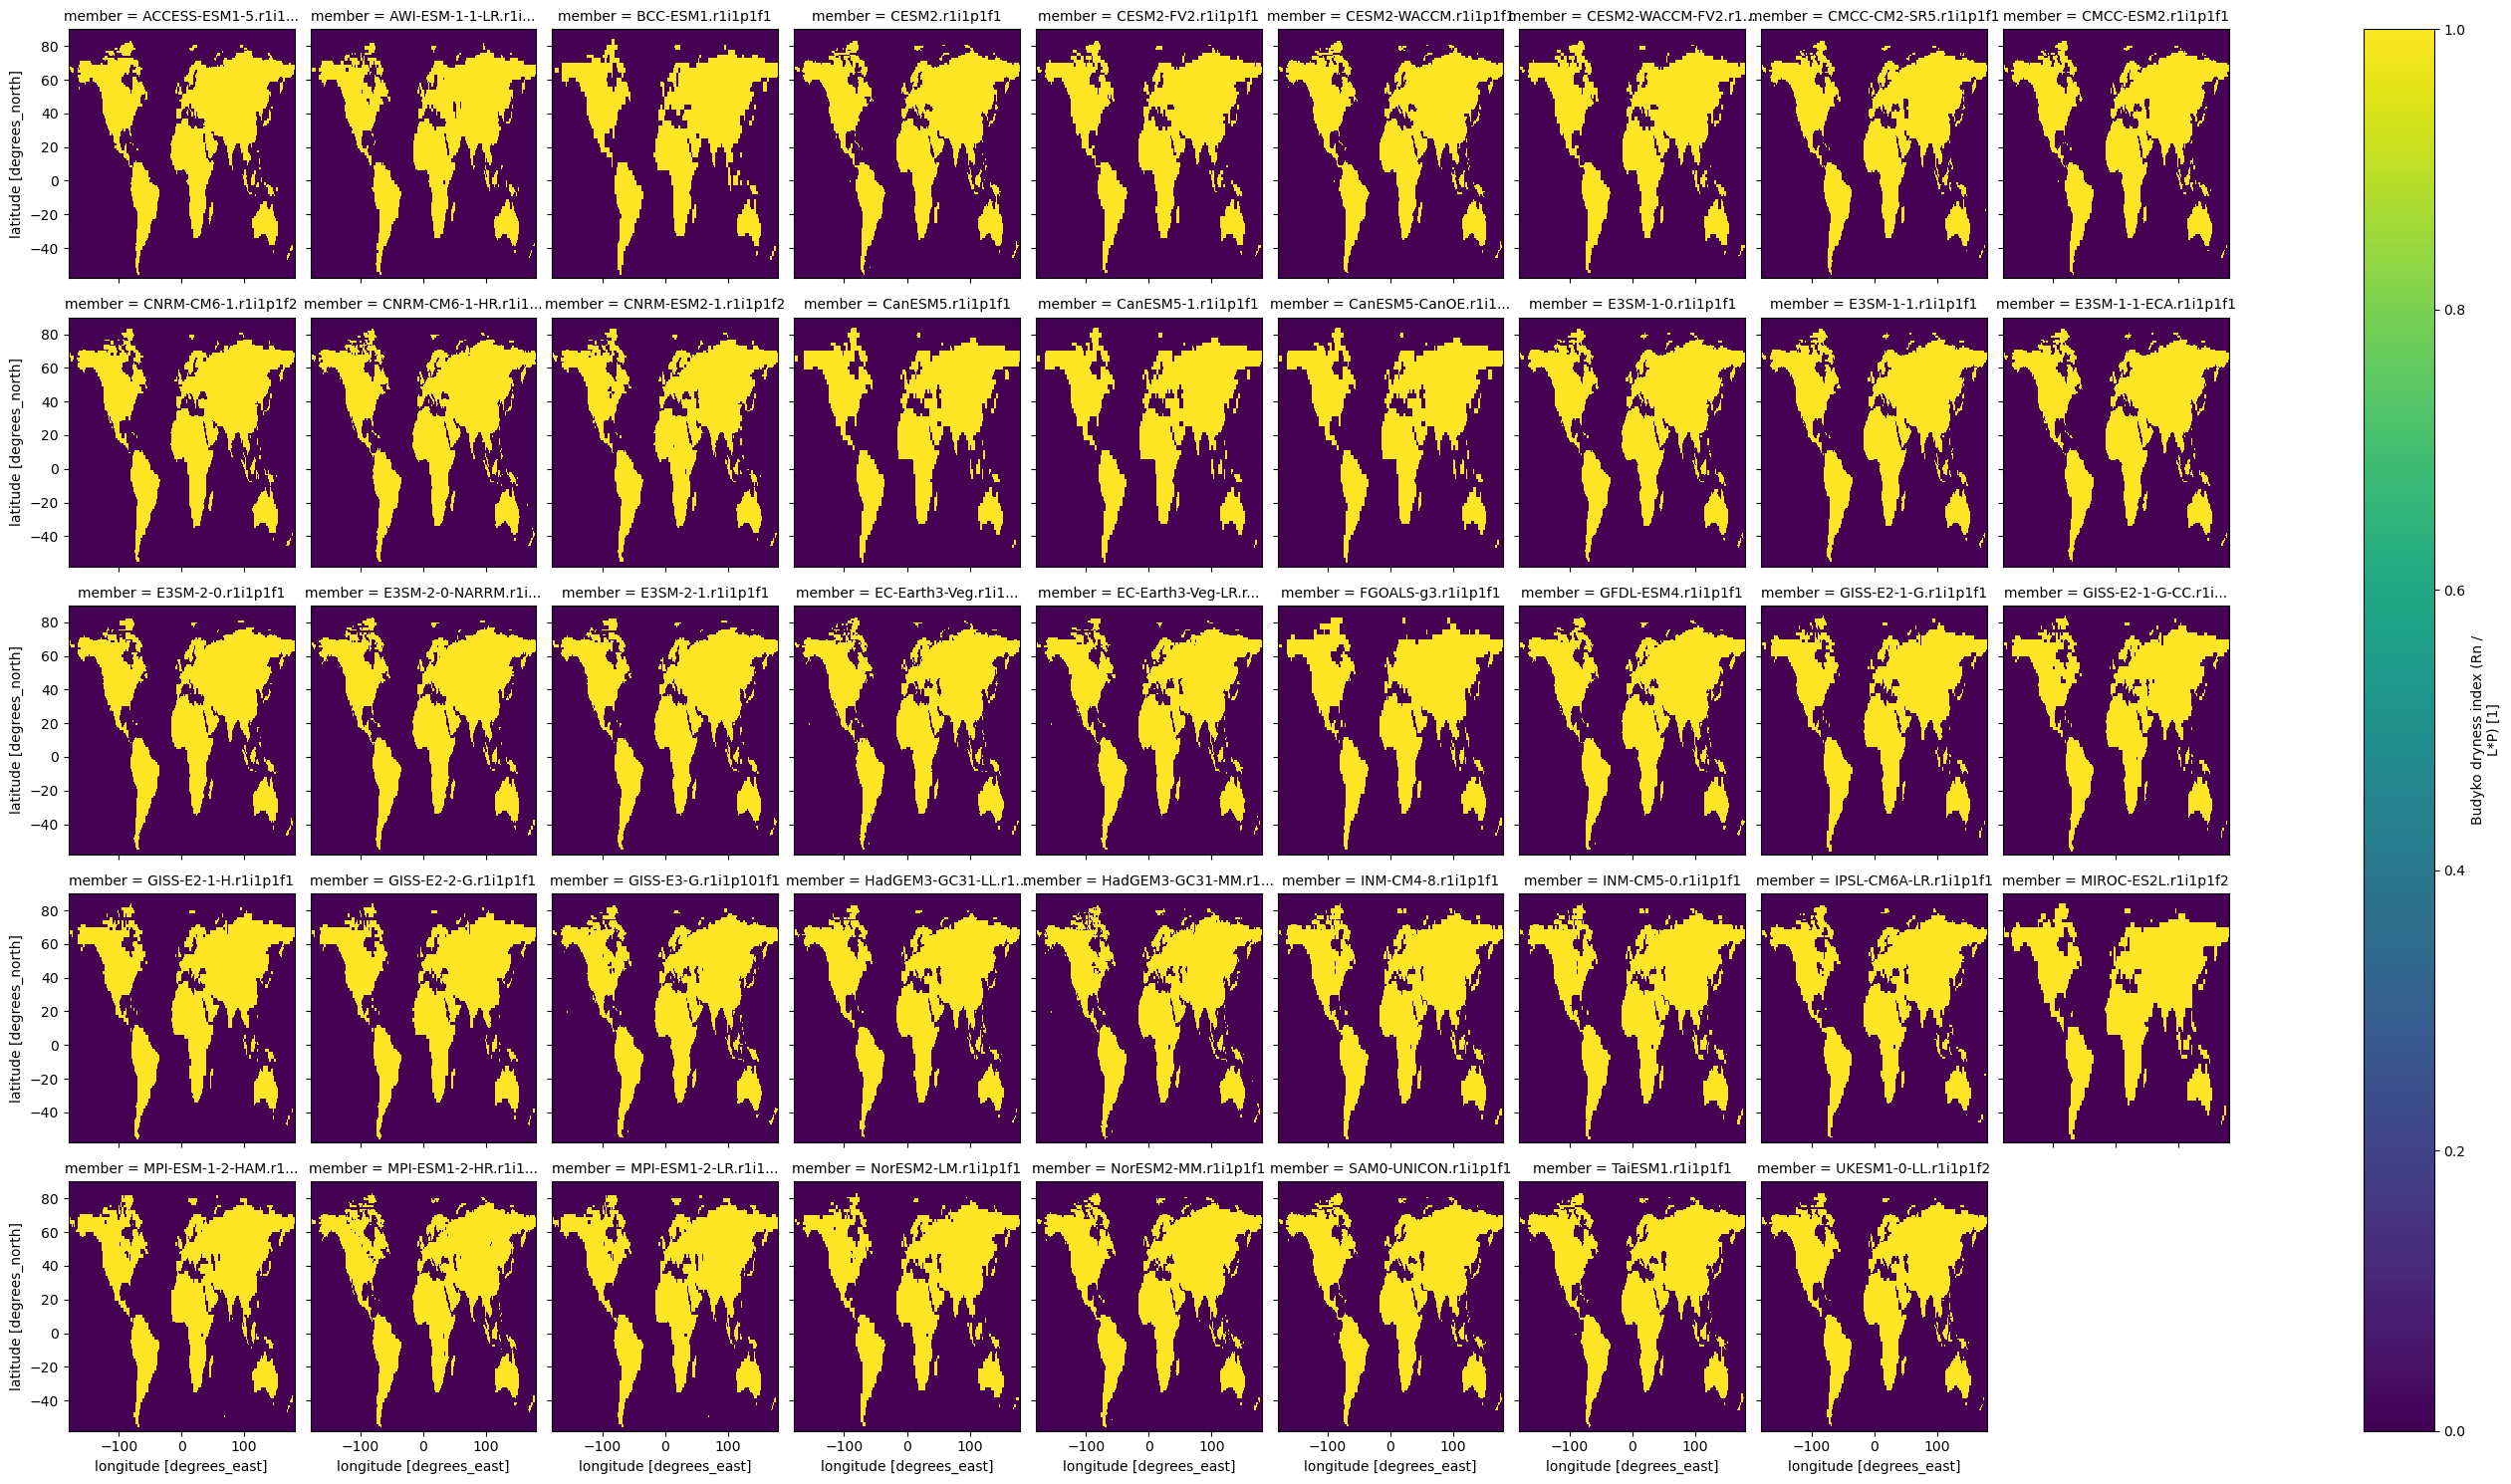

In [29]:
np.isfinite(inputs["cmip"]["ai"]).plot(col="member", col_wrap=9)

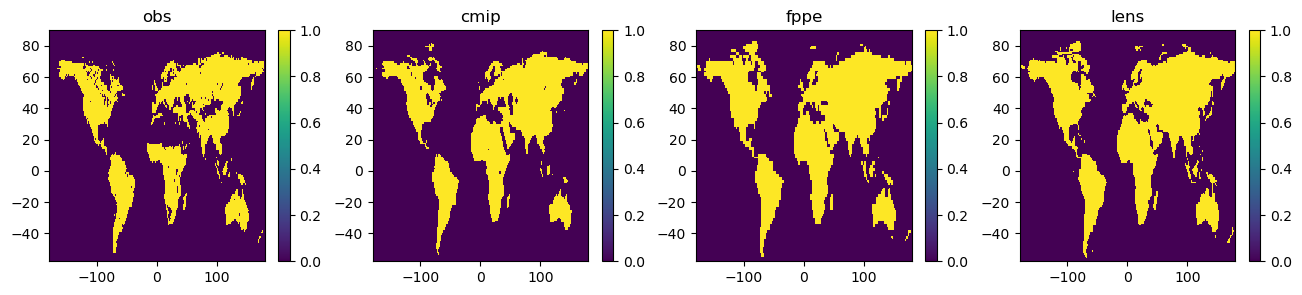

In [11]:
fig, axs = plt.subplots(1, len(valid.keys()), figsize=(16, 3))
for ax, (fam, val) in zip(axs, valid.items()):
    val.plot(ax=ax, add_labels=False)
    ax.set_title(fam)